In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits

# Tai du lieu chu so viet tay
digits = load_digits(n_class=10)

# Kiem tra thong tin du lieu
print("So mau:", digits.data.shape[0])
print("So dac trung:", digits.data.shape[1])
print("Kich thuoc anh:", digits.images[0].shape)
print("Cac nhan:", np.unique(digits.target))


So mau: 1797
So dac trung: 64
Kich thuoc anh: (8, 8)
Cac nhan: [0 1 2 3 4 5 6 7 8 9]


In [2]:

# Hien thi ma tran pixel cua anh dau tien
print(digits.data[0].reshape(8, 8))

# Hien thi 9 nhan dau tien
print("9 nhan dau tien:")
print(digits.target[:9])


[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
9 nhan dau tien:
[0 1 2 3 4 5 6 7 8]


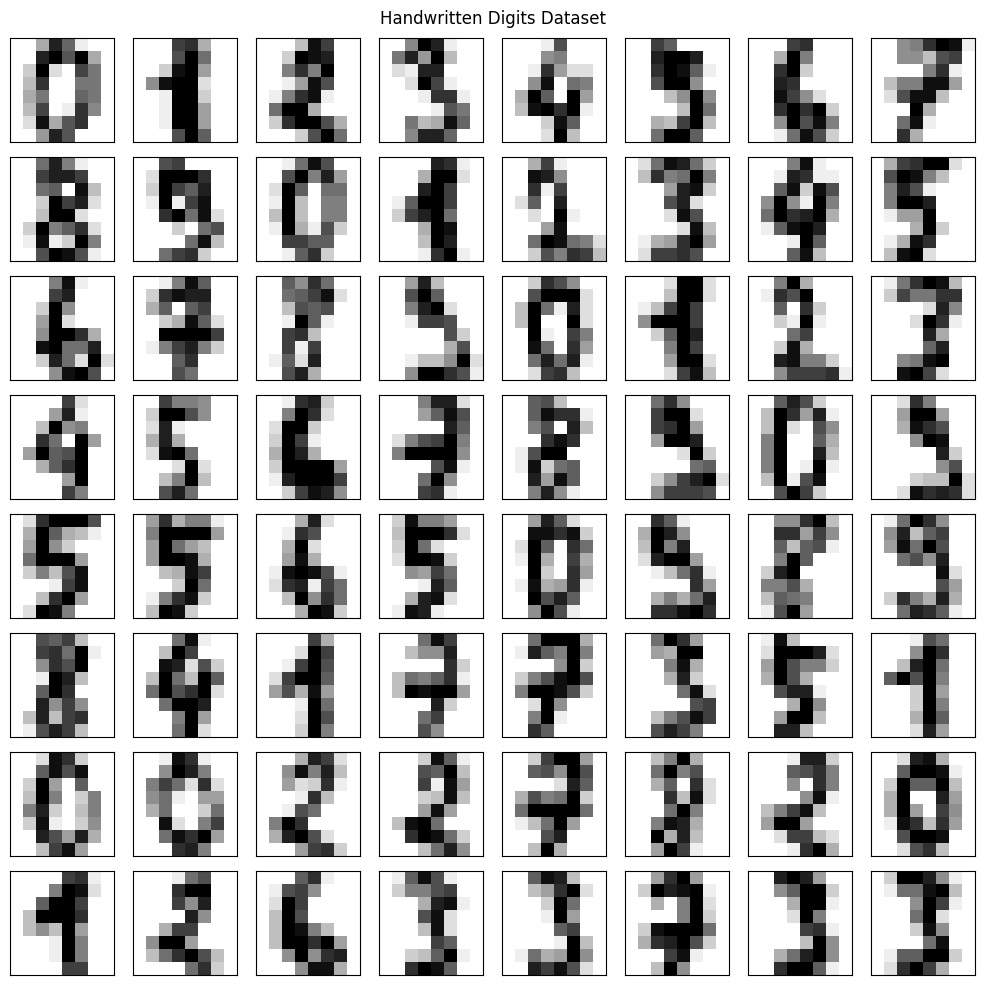

In [3]:

# Hien thi 64 anh dau tien
fig, ax = plt.subplots(8, 8, figsize=(10, 10))

for i, axi in enumerate(ax.flat):
    axi.imshow(digits.images[i], cmap='binary')
    axi.set(xticks=[], yticks=[])

plt.suptitle("Handwritten Digits Dataset")
plt.tight_layout()
plt.show()


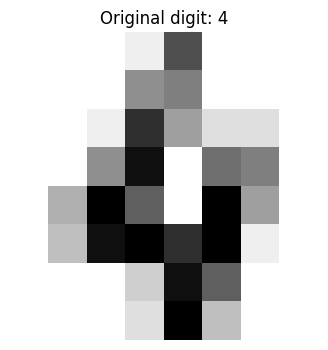

In [4]:

import matplotlib.pyplot as plt

# Ham hien thi mot chu so viet tay
def view_digit(index):
    plt.figure(figsize=(4, 4))

    plt.imshow(
        digits.images[index],
        cmap=plt.cm.gray_r
    )

    plt.title(
        'Original digit: ' + str(digits.target[index])
    )

    plt.axis('off')
    plt.show()

# Hien thi anh tai vi tri thu 4
view_digit(4)


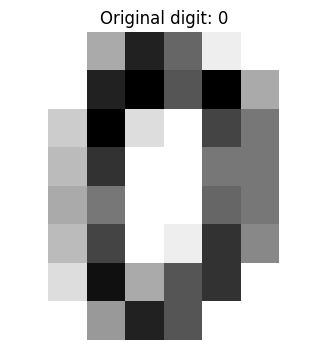

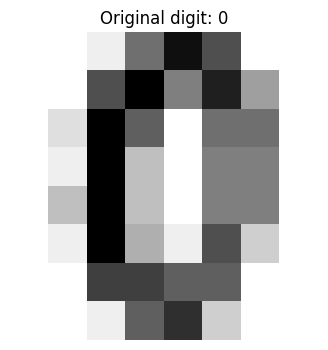

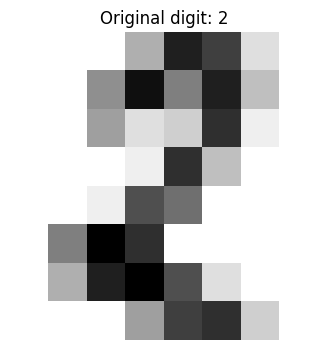

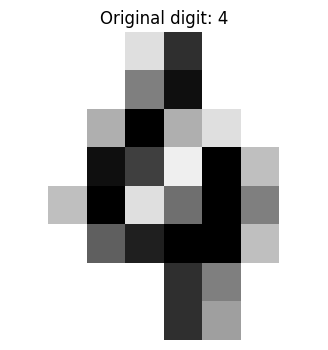

In [5]:

view_digit(0)
view_digit(10)
view_digit(50)
view_digit(100)


In [6]:

from sklearn import svm
import numpy as np

# Lay du lieu dac trung va nhan
main_data = digits['data']
targets = digits['target']

# Chia du lieu huan luyen va kiem tra
X_train = main_data[:1500]
X_test = main_data[1500:]

y_train = targets[:1500]
y_test = targets[1500:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (1500, 64)
X_test: (297, 64)
y_train: (1500,)
y_test: (297,)


In [7]:

from sklearn.preprocessing import StandardScaler

# Khoi tao StandardScaler
scaler = StandardScaler()

# Chuan hoa tap train
X_train_scaled = scaler.fit_transform(X_train)

# Chuan hoa tap test
X_test_scaled = scaler.transform(X_test)

print("Chuan hoa du lieu thanh cong!")
print("Train:", X_train_scaled.shape)
print("Test:", X_test_scaled.shape)


Chuan hoa du lieu thanh cong!
Train: (1500, 64)
Test: (297, 64)


In [9]:

from sklearn.svm import SVC

# Khoi tao mo hinh SVM
svc = SVC(gamma=0.001, C=100)

# Huan luyen mo hinh
svc.fit(X_train_scaled, y_train)

print("Huan luyen SVM thanh cong!")


Huan luyen SVM thanh cong!


In [10]:

# Du doan tren tap test
predictions = svc.predict(X_test_scaled)

print("Nhan thuc te:", y_test[:10])
print("Nhan du doan:", predictions[:10])


Nhan thuc te: [1 7 4 6 3 1 3 9 1 7]
Nhan du doan: [1 7 4 6 3 1 3 9 1 7]


In [11]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Tao ma tran nham lan
cm = confusion_matrix(y_test, predictions)

# Chuyen thanh DataFrame
conf_matrix = pd.DataFrame(
    cm,
    index=range(10),
    columns=range(10)
)

print("Confusion Matrix:")
display(conf_matrix)


Confusion Matrix:


,0,1,2,3,4,5,6,7,8,9
0,26,0,0,0,0,0,1,0,0,0
1,0,31,0,0,0,0,0,0,0,0
2,0,0,27,0,0,0,0,0,0,0
3,0,0,0,20,0,3,0,0,7,0
4,0,0,0,0,30,0,0,0,2,1
5,0,1,0,0,0,29,0,0,0,0
6,0,1,0,0,0,0,29,0,0,0
7,0,0,0,1,0,0,0,29,0,0
8,0,2,0,0,0,0,0,1,25,0
9,0,1,0,1,0,0,0,2,1,26


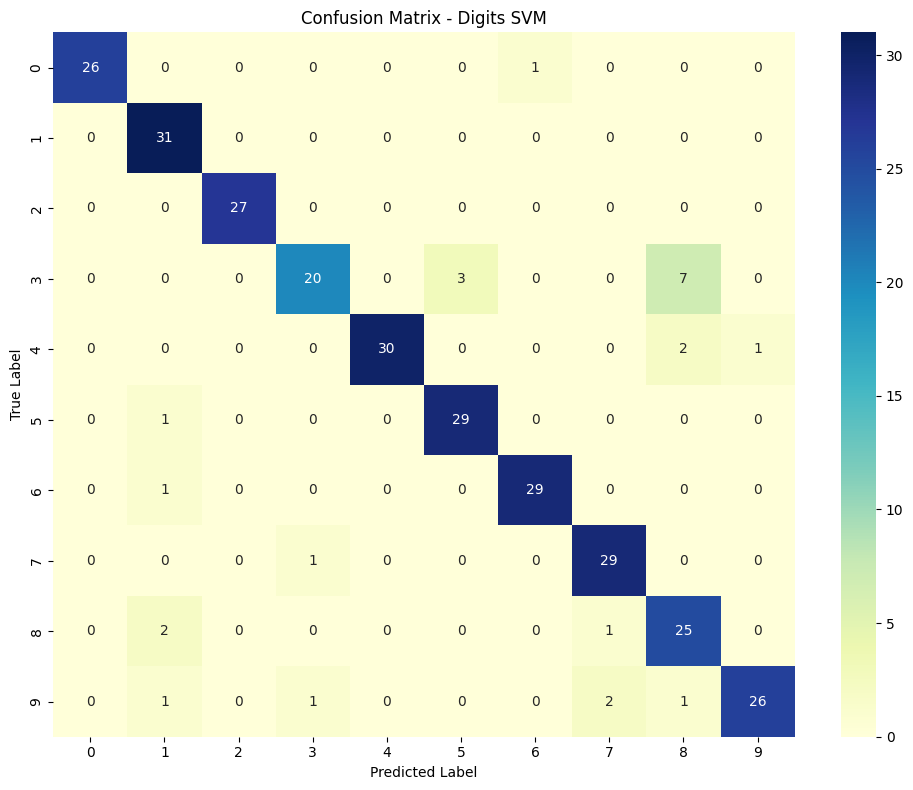

In [12]:

import seaborn as sns
import matplotlib.pyplot as plt

# Ve Confusion Matrix Heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Confusion Matrix - Digits SVM")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()


In [14]:

import numpy as np
from sklearn.metrics import accuracy_score

# Dem so mau du doan dung
correct = np.sum(y_test == predictions)

# Dem so mau du doan sai
incorrect = np.sum(y_test != predictions)

# Tinh Accuracy
accuracy = accuracy_score(y_test, predictions)

print("Tong so mau test:", len(y_test))
print("So mau du doan dung:", correct)
print("So mau du doan sai:", incorrect)
print(f"Accuracy: {accuracy * 100:.2f}%")


Tong so mau test: 297
So mau du doan dung: 272
So mau du doan sai: 25
Accuracy: 91.58%


In [15]:

from sklearn.metrics import classification_report

# Danh gia mo hinh SVM
report = classification_report(
    y_test,
    predictions,
    digits=4
)

print("===== CLASSIFICATION REPORT =====")
print(report)


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0     1.0000    0.9630    0.9811        27
           1     0.8611    1.0000    0.9254        31
           2     1.0000    1.0000    1.0000        27
           3     0.9091    0.6667    0.7692        30
           4     1.0000    0.9091    0.9524        33
           5     0.9062    0.9667    0.9355        30
           6     0.9667    0.9667    0.9667        30
           7     0.9062    0.9667    0.9355        30
           8     0.7143    0.8929    0.7937        28
           9     0.9630    0.8387    0.8966        31

    accuracy                         0.9158       297
   macro avg     0.9227    0.9170    0.9156       297
weighted avg     0.9232    0.9158    0.9152       297



In [16]:

import pandas as pd
from sklearn.metrics import classification_report

# Tao bao cao duoi dang dictionary
report_dict = classification_report(
    y_test,
    predictions,
    output_dict=True
)

# Chuyen thanh bang DataFrame
df_report = pd.DataFrame(report_dict).transpose()

display(df_report.round(4))


,precision,recall,f1-score,support
0,1.0000,0.9630,0.9811,27.0000
1,0.8611,1.0000,0.9254,31.0000
2,1.0000,1.0000,1.0000,27.0000
3,0.9091,0.6667,0.7692,30.0000
4,1.0000,0.9091,0.9524,33.0000
5,0.9062,0.9667,0.9355,30.0000
6,0.9667,0.9667,0.9667,30.0000
7,0.9062,0.9667,0.9355,30.0000
8,0.7143,0.8929,0.7937,28.0000
9,0.9630,0.8387,0.8966,31.0000


In [17]:

from pathlib import Path
from sklearn.metrics import accuracy_score

output_dir = Path("/kaggle/working")

# Tinh do chinh xac
accuracy = accuracy_score(y_test, predictions)

# Luu bao cao TXT
with open(
    output_dir / "digits_evaluation.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("HANDWRITTEN DIGITS SVM EVALUATION\n\n")
    f.write("Model: SVC(kernel='rbf', gamma=0.001, C=100)\n")
    f.write("Scaling: StandardScaler\n")
    f.write(f"Training samples: {len(y_train)}\n")
    f.write(f"Testing samples: {len(y_test)}\n")
    f.write(f"Accuracy: {accuracy * 100:.2f}%\n\n")
    f.write("Classification Report:\n")
    f.write(report)

# Luu bao cao CSV
df_report.to_csv(
    output_dir / "digits_classification_report.csv",
    encoding="utf-8-sig"
)

print("Da luu bao cao TXT va CSV thanh cong!")


Da luu bao cao TXT va CSV thanh cong!


### Nhận xét kết quả mô hình SVM trên Handwritten Digits

**1. Mô tả dữ liệu**

Tập dữ liệu Handwritten Digits gồm 1.797 hình ảnh chữ số viết tay từ 0 đến 9. Mỗi ảnh có kích thước 8×8 pixel, được biểu diễn bằng 64 đặc trưng.

Dữ liệu được chia thành 1.500 mẫu huấn luyện và 297 mẫu kiểm tra.

**2. Xây dựng mô hình**

Sử dụng thuật toán Support Vector Machine với mô hình SVC, kernel RBF, gamma = 0.001 và C = 100. Dữ liệu được chuẩn hóa bằng StandardScaler trước khi huấn luyện.

**3. Kết quả đánh giá**

- Accuracy: **91,58%**.
- Số mẫu dự đoán đúng: **272/297**.
- Số mẫu dự đoán sai: **25/297**.
- Macro Precision: **92,27%**.
- Macro Recall: **91,70%**.
- Macro F1-score: **91,56%**.

Dựa trên Confusion Matrix, mô hình nhận diện chính xác toàn bộ các mẫu chữ số 1 và 2 trong tập kiểm tra. Tuy nhiên, mô hình gặp khó khăn khi nhận diện chữ số 3, với Recall chỉ đạt 66,67%. Đáng chú ý, có 7 mẫu chữ số 3 bị nhầm thành chữ số 8.

**4. Kết luận**

Mô hình SVM đạt độ chính xác 91,58% khi phân loại chữ số viết tay trên tập kiểm tra gồm 297 mẫu. Kết quả cho thấy SVM có khả năng nhận diện chữ số tương đối tốt, nhưng vẫn tồn tại nhầm lẫn giữa các chữ số có hình dạng tương tự nhau. Có thể cải thiện mô hình thông qua tối ưu tham số C, gamma và kernel.